# Practical 4 · Random forests, boosting, tuning and a fair comparison (churn)

**Goal:** fix the single tree's weaknesses by combining many trees, tune them with **RandomizedSearchCV**, and compare **every model so far** fairly, then pick a winner and test it once.

Steps 0–7 are the same as Practicals 2 and 3.

## Steps 0–7 · Load, clean, split

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (8, 4.5)

# Step 1 - load
url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/telco-churn.csv'
if not os.path.exists('telco-churn.csv'):
    urlretrieve(url, 'telco-churn.csv')
df = pd.read_csv('telco-churn.csv')

# Step 4 - clean: blank TotalCharges belong to brand-new customers (tenure 0) -> they have paid 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# Step 3 - target and features (drop the ID column)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# Step 6 - stratified split (same split as Practical 2)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Step 7 - feature types
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print('Train', X_train.shape, '| Test', X_test.shape, '| churn rate', round(y_train.mean(), 3))

Train (5634, 19) | Test (1409, 19) | churn rate 0.265


## Steps 9–12 · Preprocessing pipelines (one for linear models, one for trees)

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

onehot = Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocess_linear = ColumnTransformer([('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
                                       ('cat', onehot, categorical_cols)])
preprocess_tree = ColumnTransformer([('num', SimpleImputer(strategy='median'), numeric_cols), ('cat', onehot, categorical_cols)])
def make(pre, model):
    return Pipeline([('preprocess', pre), ('model', model)])
print('ready')

ready


## Step 15 · The wisdom of the crowd: averaging trees
A single full-grown tree overfits (Practical 3: validation AUC ≈ 0.66). What if we grow **many** trees, each on a different random sample of customers, and **average** their votes?

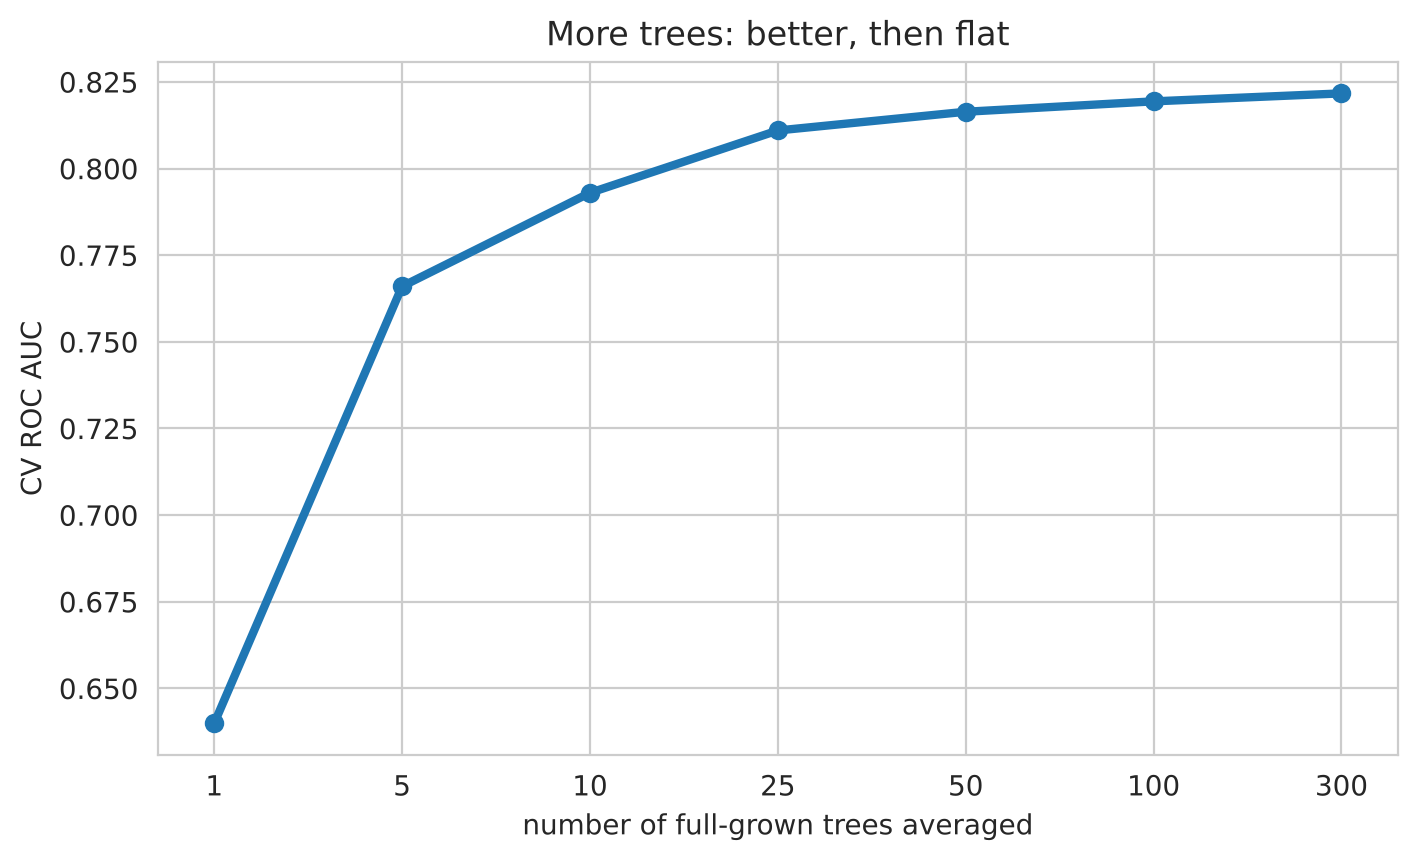

,number of trees,CV ROC AUC
0,1,0.6399
1,5,0.7660
2,10,0.7930
3,25,0.8110
4,50,0.8164
5,100,0.8194
6,300,0.8217


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
rows = []
from sklearn.model_selection import StratifiedKFold, cross_val_score
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for n in [1, 5, 10, 25, 50, 100, 300]:
    s = cross_val_score(make(preprocess_tree, RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)),
                        X_train, y_train, cv=folds, scoring='roc_auc').mean()
    rows.append({'number of trees': n, 'CV ROC AUC': round(s, 4)})
crowd = pd.DataFrame(rows)
plt.plot(crowd['number of trees'].astype(str), crowd['CV ROC AUC'], 'o-', linewidth=3)
plt.xlabel('number of full-grown trees averaged'); plt.ylabel('CV ROC AUC'); plt.title('More trees: better, then flat'); plt.show()
crowd

One tree ≈ 0.64. Averaging 25 trees jumps above 0.81. After ~100 trees the curve is flat: **adding trees never makes a forest overfit**; it only costs time.

**Why it works:** each tree overfits to **different** noise (it saw a different random sample, and at each split it may only consider a random subset of features). Averaging cancels the noise and keeps the real pattern.

## Step 16 · A free validation score: out-of-bag (OOB)
Each tree's random sample leaves out about 37% of customers. Scoring every customer only with the trees that never saw them gives a free estimate of performance, with no extra cross-validation.

In [4]:
rf_oob = make(preprocess_tree, RandomForestClassifier(n_estimators=300, min_samples_leaf=10, oob_score=True, random_state=42, n_jobs=-1)).fit(X_train, y_train)
oob_proba = rf_oob.named_steps['model'].oob_decision_function_[:, 1]
print('OOB ROC AUC:', round(roc_auc_score(y_train, oob_proba), 4))
print('5-fold CV ROC AUC:', round(cross_val_score(make(preprocess_tree, RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=-1)), X_train, y_train, cv=folds, scoring='roc_auc').mean(), 4))

OOB ROC AUC: 0.8481


5-fold CV ROC AUC: 0.8472


The OOB score and 5-fold cross-validation agree closely, and OOB cost no extra training.

## Step 18 · Tune the forest with RandomizedSearchCV
A forest has several settings. Trying every combination (GridSearch) would be slow, so **RandomizedSearchCV** tries a random sample of combinations.
- `n_estimators`: number of trees
- `min_samples_leaf`: smallest leaf (bigger = simpler trees)
- `max_features`: how many features each split may consider (smaller = more different trees)
- `max_depth`: maximum depth of each tree

In [5]:
from sklearn.model_selection import RandomizedSearchCV
space = {'model__n_estimators': [200, 300, 500],
         'model__min_samples_leaf': [1, 3, 5, 10, 20, 50],
         'model__max_features': ['sqrt', 0.2, 0.4, 0.7],
         'model__max_depth': [None, 8, 12, 20]}
search = RandomizedSearchCV(make(preprocess_tree, RandomForestClassifier(random_state=42, n_jobs=-1)), space,
                            n_iter=15, cv=folds, scoring='roc_auc', random_state=42).fit(X_train, y_train)
print('Best settings:', search.best_params_)
print('Best CV ROC AUC:', round(search.best_score_, 4))
pd.DataFrame(search.cv_results_)[['param_model__min_samples_leaf', 'param_model__max_features', 'param_model__max_depth', 'mean_test_score']] \
  .sort_values('mean_test_score', ascending=False).head(6).round(4)

Best settings: {'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_features': 'sqrt', 'model__max_depth': 12}
Best CV ROC AUC: 0.8482


,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,mean_test_score
1,20,sqrt,12,0.8482
8,3,sqrt,8,0.8476
9,50,0.4,12,0.8473
11,50,0.2,None,0.8469
7,10,0.2,12,0.8469
5,10,sqrt,None,0.8467


15 of 4 × 6 × 4 × 3 = 288 combinations tried. Notice which settings the top rows share: usually a **larger** `min_samples_leaf` (simpler trees) helps on this data.

## Step 15 · Boosting: trees that fix each other's mistakes
**Gradient boosting** builds small trees **one after another**; each new tree learns from the mistakes of all the trees before it. scikit-learn's `HistGradientBoostingClassifier` is a fast modern version (similar to LightGBM).

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
boost_default = make(preprocess_tree, HistGradientBoostingClassifier(random_state=42))
boost_tuned = make(preprocess_tree, HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                                   min_samples_leaf=40, early_stopping=True, random_state=42))
for name, m in [('boosting, default settings', boost_default), ('boosting, tuned', boost_tuned)]:
    print(name, round(cross_val_score(m, X_train, y_train, cv=folds, scoring='roc_auc').mean(), 4))

boosting, default settings 0.8364


boosting, tuned 0.8478


Note: boosting with **default** settings scores lower than the tuned version: the defaults are built for big data and overfit our 5,600 customers. Smaller learning rate + early stopping + bigger leaves fixes it.

## Step 17 · The fair contest: every model, same folds, same metrics

In [7]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

candidates = {
    'Baseline (always stays)': make(preprocess_tree, DummyClassifier(strategy='most_frequent')),
    'Logistic regression': make(preprocess_linear, LogisticRegression(max_iter=2000)),
    'Decision tree (tuned)': make(preprocess_tree, DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=42)),
    'Random forest (tuned)': search.best_estimator_,
    'Gradient boosting (tuned)': boost_tuned,
}
board = {}
for name, m in candidates.items():
    cv = cross_validate(m, X_train, y_train, cv=folds, scoring=('roc_auc', 'average_precision', 'neg_log_loss'))
    board[name] = {'ROC AUC': cv['test_roc_auc'].mean(), 'AUC spread (±)': cv['test_roc_auc'].std(),
                   'PR AUC': cv['test_average_precision'].mean(), 'log loss': -cv['test_neg_log_loss'].mean()}
board = pd.DataFrame(board).T.sort_values('ROC AUC', ascending=False).round(4)
board

,ROC AUC,AUC spread (±),PR AUC,log loss
Random forest (tuned),0.8482,0.0097,0.6624,0.4154
Gradient boosting (tuned),0.8478,0.0106,0.6633,0.4138
Logistic regression,0.8462,0.0126,0.6617,0.4166
Decision tree (tuned),0.8329,0.0103,0.6259,0.4800
Baseline (always stays),0.5000,0.0000,0.2654,9.5643


**How to read the leaderboard honestly:**
- The top three models are within about **0.002 AUC** of each other, **smaller than the ± spread** between folds. On this simple dataset, ensembles barely beat logistic regression.
- The single tree is clearly behind; the baseline is useless (0.5).
- When scores are this close, decide with other criteria: **simplicity, explainability, speed, probability quality** (log loss).

## Step 16 · Feature importance of the forest (permutation, on test data)

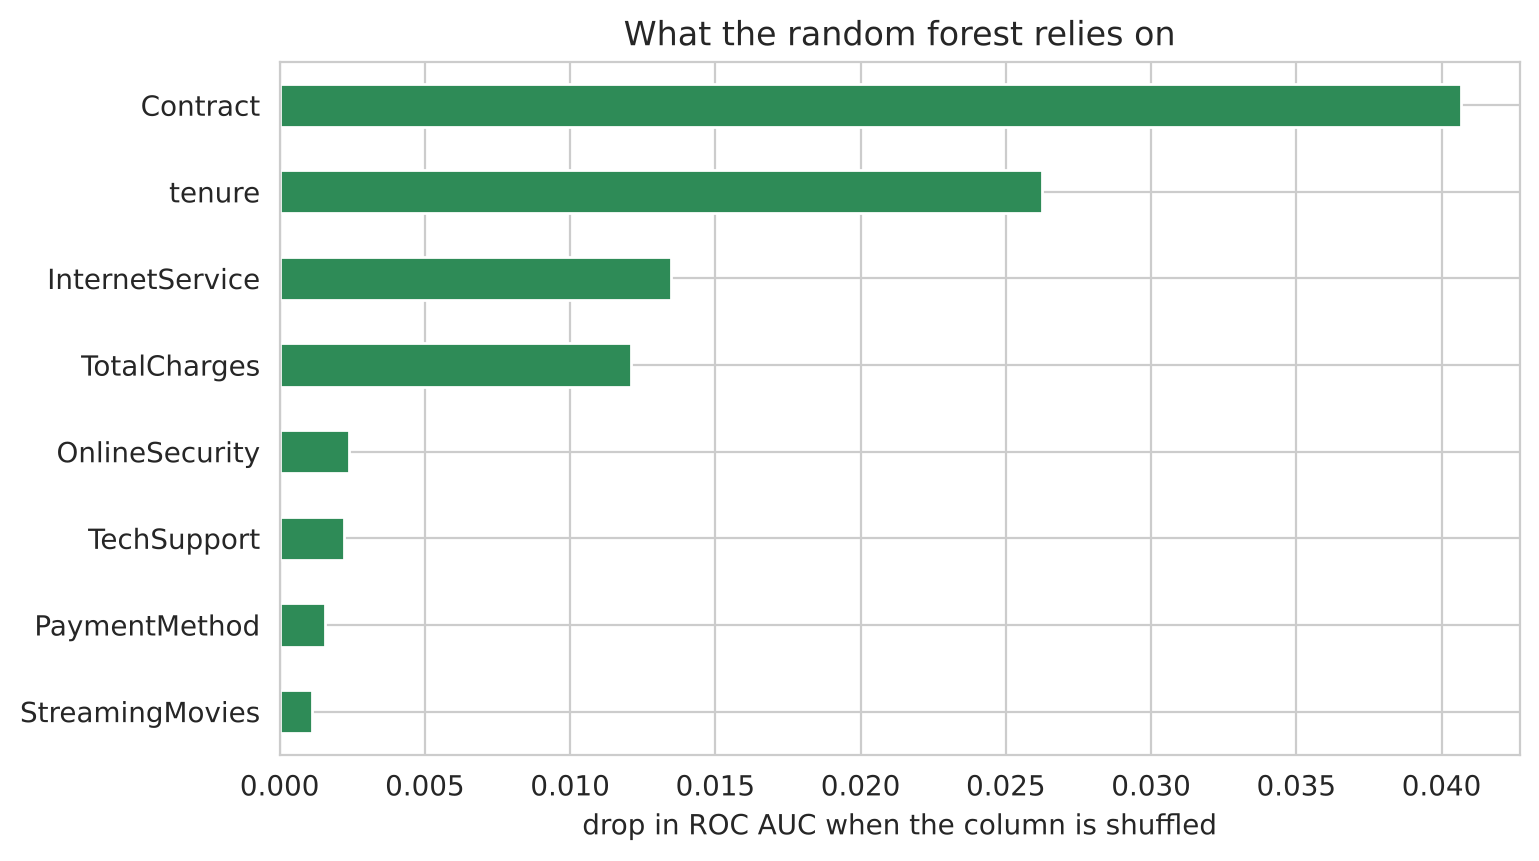

In [8]:
from sklearn.inspection import permutation_importance
best_rf = search.best_estimator_
perm = permutation_importance(best_rf, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=0)
pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(8).plot.barh(color='seagreen')
plt.xlabel('drop in ROC AUC when the column is shuffled'); plt.title('What the random forest relies on'); plt.show()

## Step 19 · Choose and test once
We choose by cross-validation (above). Let's open the test set for the top three, **only to report**, not to choose again.

In [9]:
report = {}
for name in ['Logistic regression', 'Random forest (tuned)', 'Gradient boosting (tuned)']:
    m = candidates[name].fit(X_train, y_train)
    report[name] = {'test ROC AUC': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
pd.DataFrame(report).T.round(4)

,test ROC AUC
Logistic regression,0.8421
Random forest (tuned),0.8451
Gradient boosting (tuned),0.8458


The test results agree with cross-validation: all three are close. **Decision:** if the business needs explanations (why is this customer risky?), logistic regression is a strong, simple choice. If every bit of accuracy matters and explanations can come from permutation importance, the tuned ensemble is fine. **Both are defensible: write your reason down.**

## Step 20 · Save the chosen model

In [10]:
import joblib
final = candidates['Gradient boosting (tuned)'].fit(X_train, y_train)
joblib.dump(final, 'churn_boosting.joblib')
print('Saved churn_boosting.joblib')

Saved churn_boosting.joblib


## Summary
| Idea | What we saw |
|---|---|
| Averaging many trees (random forest) | one tree ≈ 0.64 AUC → 300 trees ≈ 0.82 → tuned forest ≈ 0.85 |
| More trees never overfit a forest | the curve goes flat, not down |
| OOB score | free validation, agrees with CV |
| RandomizedSearchCV | tunes many settings quickly |
| Boosting | strong when tuned; defaults can overfit small data |
| Fair comparison | top models within noise → choose by simplicity and needs |

## Exercises
1. In the RandomizedSearchCV, raise `n_iter` to 40. Does the best score improve enough to be worth the extra time?
2. Add `class_weight='balanced'` to the random forest. What happens to recall at threshold 0.5?
3. Install XGBoost (`pip install xgboost`) and add `XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3)` to the contest.